# Практическая работа № 3

**Тема исследования:** определение принадлежности самолёта к гражданской или военной авиации по изображению с использованием Vision-Language Models (VLM).
**Исследуемые модели:** Qwen2.5-VL-3B-Instruct и SmolVLM2-2.2B-Instruct

## Цель и задачи исследования

**Цель** — оценить и сопоставить качество двух Vision-Language Models при определении типа самолёта по фотографии.

Для достижения цели решаются следующие задачи:
1. Подготовить и проверить размеченный набор изображений.
2. Настроить единый запрос (prompt), обеспечивающий одинаковые условия классификации.
3. Получить предсказания двух моделей и сохранить результаты.
4. Рассчитать метрики качества и построить матрицы ошибок.
5. Сопоставить результаты на всей выборке и на подгруппах разной сложности.
6. Проанализировать ошибки и сформулировать выводы об ограничениях эксперимента.

## Организация эксперимента

Используются 30 изображений: 8 простых и 22 нетривиальных случая. Каждое изображение имеет истинную метку в `labels.csv`. Обе модели получают одинаковый текстовый запрос и обрабатывают одни и те же изображения. Для воспроизводимости генерация выполняется без случайной выборки (`do_sample=False`).

## 1. Программная среда и используемые библиотеки

На данном этапе устанавливаются библиотеки для загрузки мультимодальных моделей, обработки изображений, работы с таблицами и вычисления метрик. Проверяется доступность GPU, поскольку инференс моделей выполняется на графическом ускорителе.

In [11]:
!pip -q install -U transformers accelerate num2words

import torch
print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU НЕ НАЙДЕН: включите T4 в Runtime → Change runtime type и перезапустите.")

PyTorch: 2.14.1+cu130
GPU: Tesla T4


## 2. Набор данных и предварительная проверка

Экспериментальная выборка содержит 30 фотографий самолётов и файл разметки `labels.csv`. Для каждого изображения задаётся истинный класс (`military` или `civil`), название модели самолёта и текстовое примечание. По примечанию выделяются нетривиальные случаи.

Для повторного запуска данные необходимо поместить в архив. Архив может содержать изображения и `labels.csv` в корневой папке либо в одной общей вложенной папке. После загрузки проверяются число записей, наличие файлов и распределение классов. Следующая визуализация позволяет проверить состав выборки.

In [12]:
import os, glob, zipfile
from google.colab import files

uploaded = files.upload()
zip_name = next(iter(uploaded))

DATA_DIR = "planes"
os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(zip_name) as z:
    z.extractall(DATA_DIR)

LABELS_PATH = glob.glob(f"{DATA_DIR}/**/labels.csv", recursive=True)[0]
IMG_DIR = os.path.dirname(LABELS_PATH)
print("labels.csv:", LABELS_PATH)

Saving dataset.zip to dataset (1).zip
labels.csv: planes/dataset/labels.csv


In [14]:
import pandas as pd

labels = pd.read_csv(LABELS_PATH, encoding="utf-8-sig")
# «нетривиальный» случай определяем по пометке в столбце note
labels["hard"] = labels["note"].fillna("").str.contains("нетривиальный")

missing = [f for f in labels["file"] if not os.path.exists(os.path.join(IMG_DIR, f))]
print("Строк в labels.csv:", len(labels))
print("Не найдены файлы:", missing)
print("Классы:", labels["true_label"].value_counts().to_dict())
print("Нетривиальных случаев:", int(labels["hard"].sum()), "из", len(labels))
labels.head()

Строк в labels.csv: 30
Не найдены файлы: []
Классы: {'military': 15, 'civil': 15}
Нетривиальных случаев: 22 из 30


,file,true_label,aircraft_model,source,note,hard
0,img_01.jpg,military,Lockheed C-130 Hercules,NaN,транспортный (нетривиальный),True
1,img_02.jpg,military,Boeing C-17 Globemaster III,NaN,тяжёлый транспортный (нетривиальный),True
2,img_03.jpg,military,Ил-76МД,NaN,военно-транспортный (нетривиальный),True
3,img_04.jpg,military,Boeing E-3 Sentry,NaN,ДРЛО на базе Boeing 707 (нетривиальный),True
4,img_05.jpg,military,Boeing KC-135 Stratotanker,NaN,заправщик на базе Boeing 707 (нетривиальный),True


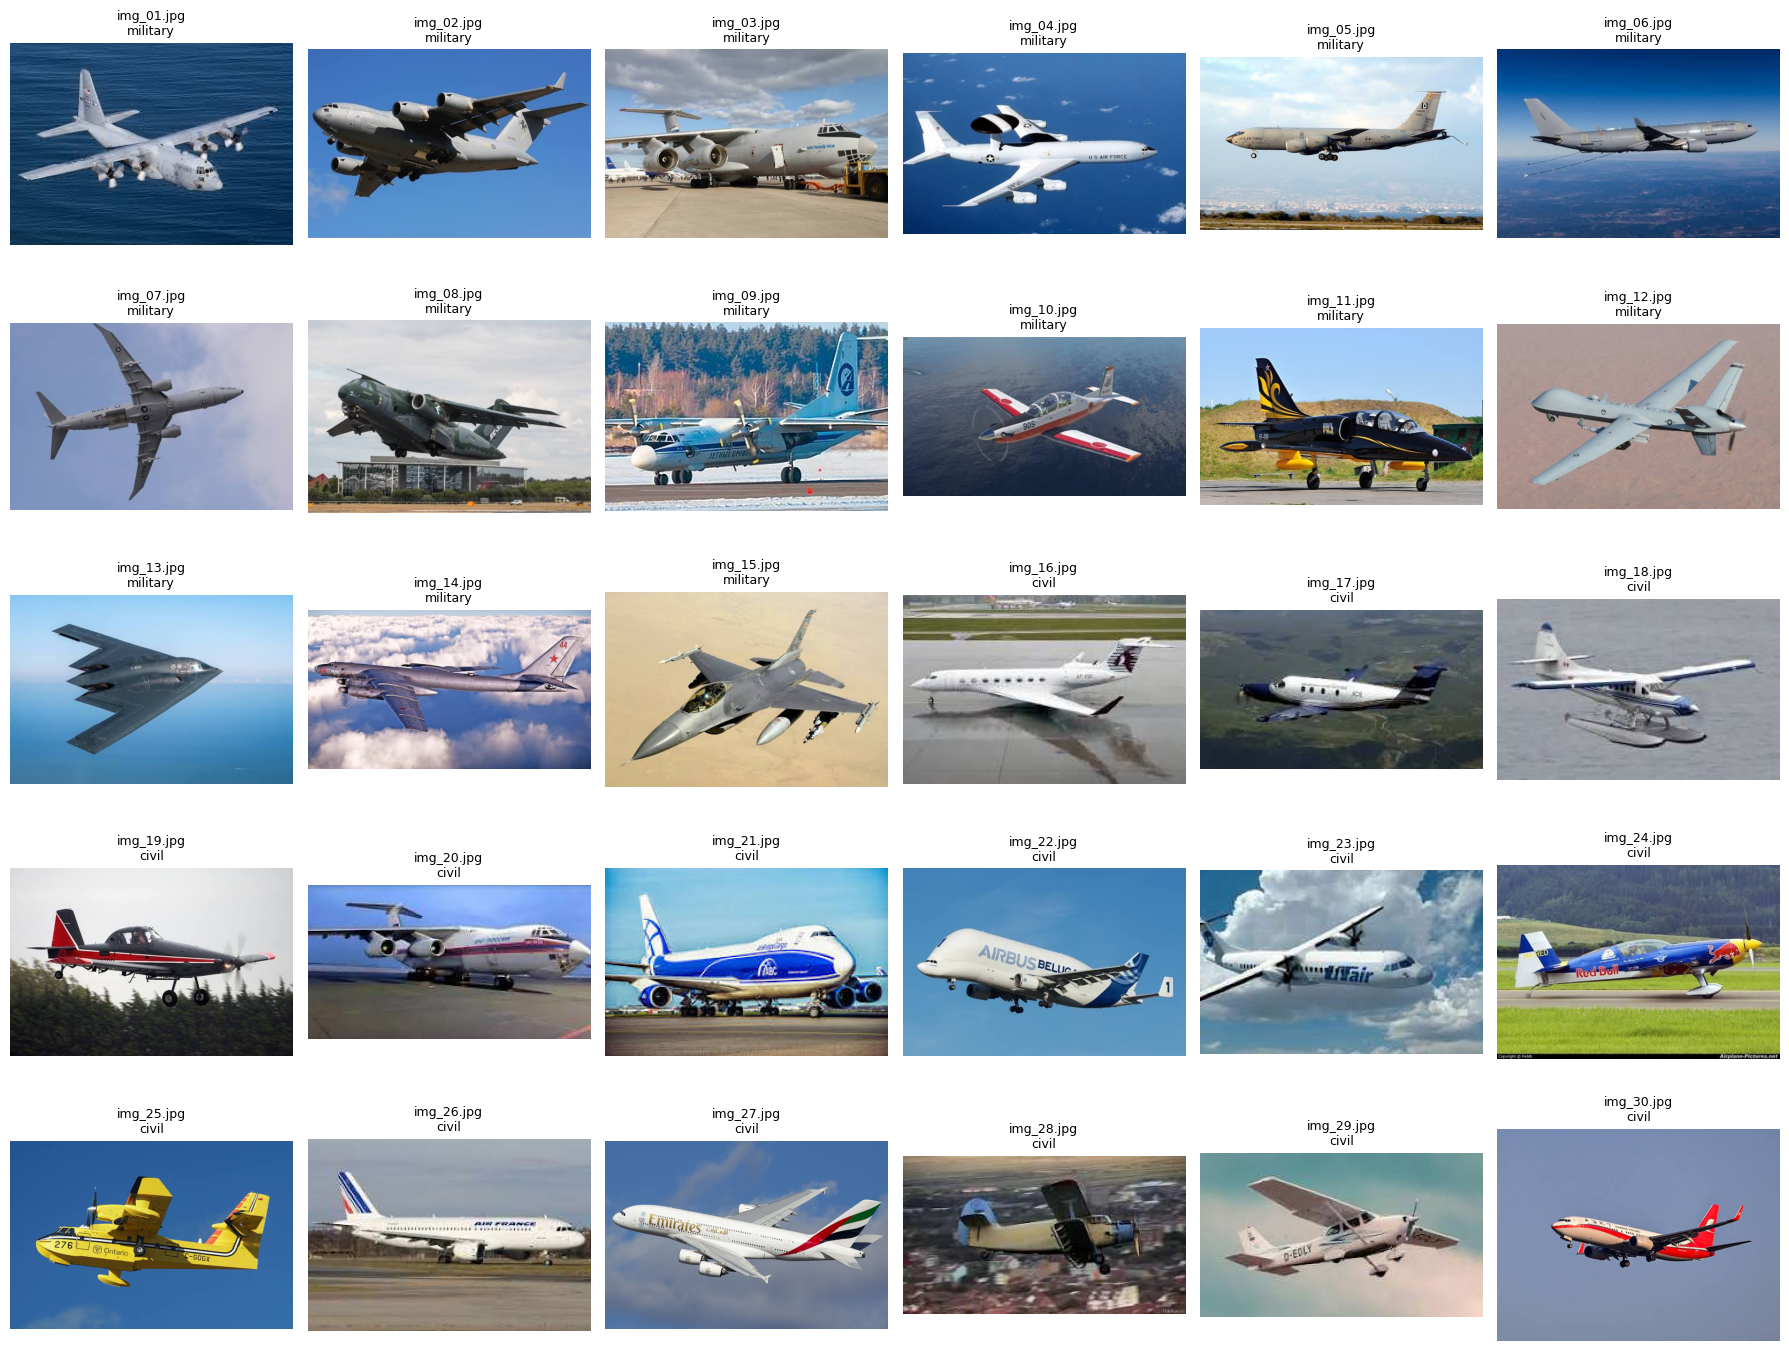

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(5, 6, figsize=(18, 14))
for ax, (_, r) in zip(axes.ravel(), labels.iterrows()):
    ax.imshow(Image.open(os.path.join(IMG_DIR, r["file"])).convert("RGB"))
    ax.set_title(f'{r["file"]}\n{r["true_label"]}', fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Методика классификации и обработка ответов

Для обеих моделей используется единый англоязычный prompt с определениями гражданского и военного самолёта. Это позволяет сравнивать модели при одинаковых условиях постановки задачи. В ответе запрашивается JSON с предсказанной меткой, оценкой уверенности и кратким объяснением.

Если ответ не удаётся разобрать как JSON, применяется резервное извлечение метки `military` или `civil` из текста. Если метка не найдена, результат обозначается как `invalid` и учитывается как ошибочная классификация. Для каждой модели сохраняются предсказания, исходный ответ и время обработки.

In [16]:
import re, json, time, gc

PROMPT = (
    "Look at the aircraft in the photo and decide whether it is a MILITARY aircraft "
    "(operated by an air force, navy, army or other armed forces) or a CIVIL aircraft "
    "(airliner, cargo airline, business jet, general aviation, agricultural, sport, etc.). "
    "Note that a military aircraft is not necessarily a fighter, and a civil aircraft is not necessarily large. "
    'Answer ONLY with a JSON object of the form '
    '{"label": "military" or "civil", "confidence": a number from 0 to 1, "reason": "one short sentence"}.'
)

def norm_label(s):
    s = str(s).strip().lower()
    if s.startswith("mil"):
        return "military"
    if s.startswith(("civ", "comm")):
        return "civil"
    return None

def parse_answer(text):
    """Возвращает (label, confidence). label: military | civil | invalid."""
    label, conf = None, None
    m = re.search(r"\{.*?\}", text, flags=re.S)
    if m:
        try:
            obj = json.loads(m.group(0))
            label = norm_label(obj.get("label", ""))
            try:
                conf = float(obj.get("confidence"))
            except (TypeError, ValueError):
                conf = None
        except json.JSONDecodeError:
            pass
    if label is None:                      # запасной разбор по ключевому слову
        k = re.search(r"\b(military|civilian|civil)\b", text.lower())
        if k:
            label = norm_label(k.group(1))
    return (label or "invalid"), conf

def load_image(path, max_side=896):
    img = Image.open(path).convert("RGB")
    img.thumbnail((max_side, max_side))    # уменьшаем: быстрее и меньше памяти
    return img

def run_model(name, infer_fn, out_csv):
    rows = []
    for _, r in labels.iterrows():
        img = load_image(os.path.join(IMG_DIR, r["file"]))
        t0 = time.time()
        try:
            raw = infer_fn(img)
        except Exception as e:             # сбой не должен ронять весь прогон
            raw = f"ERROR: {e}"
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        dt = time.time() - t0
        pred, conf = parse_answer(raw)
        rows.append(dict(file=r["file"], model=name, pred=pred, confidence=conf,
                         seconds=round(dt, 2), raw=raw.replace("\n", " ")))
        print(f'{r["file"]}: true={r["true_label"]:9s} pred={pred:9s} ({dt:.1f}s)')
    df = pd.DataFrame(rows)
    df.to_csv(out_csv, index=False, encoding="utf-8-sig")
    return df

## 4. Эксперимент 1. Qwen2.5-VL-3B-Instruct

Первая модель — `Qwen/Qwen2.5-VL-3B-Instruct`, мультимодальная модель семейства Qwen. Она получает изображение самолёта и общий prompt, после чего формирует классификационный ответ. Результаты инференса сохраняются в `results_qwen.csv` для последующего анализа.

In [17]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

MODEL_A = "Qwen/Qwen2.5-VL-3B-Instruct"
NAME_A = "Qwen2.5-VL-3B"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_A, torch_dtype=torch.float16, device_map="auto")
processor = AutoProcessor.from_pretrained(MODEL_A)

def infer_qwen(img):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[img], return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=120, do_sample=False)
    gen = out[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

# проверка на одной картинке: убедитесь, что ответ осмысленный
print(infer_qwen(load_image(os.path.join(IMG_DIR, labels["file"].iloc[0]))))

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

{"label": "military", "confidence": 0.95, "reason": "The aircraft has a large size and appears to be designed for military purposes."}


In [18]:
res_a = run_model(NAME_A, infer_qwen, "results_qwen.csv")
res_a.head()

img_01.jpg: true=military  pred=military  (2.0s)
img_02.jpg: true=military  pred=military  (2.1s)
img_03.jpg: true=military  pred=military  (2.2s)
img_04.jpg: true=military  pred=military  (1.9s)
img_05.jpg: true=military  pred=military  (2.0s)
img_06.jpg: true=military  pred=military  (2.2s)
img_07.jpg: true=military  pred=military  (2.3s)
img_08.jpg: true=military  pred=military  (2.3s)
img_09.jpg: true=military  pred=military  (2.4s)
img_10.jpg: true=military  pred=military  (2.0s)
img_11.jpg: true=military  pred=military  (2.2s)
img_12.jpg: true=military  pred=military  (1.9s)
img_13.jpg: true=military  pred=military  (2.8s)
img_14.jpg: true=military  pred=military  (2.2s)
img_15.jpg: true=military  pred=military  (2.4s)
img_16.jpg: true=civil     pred=civil     (2.1s)
img_17.jpg: true=civil     pred=civil     (1.7s)
img_18.jpg: true=civil     pred=civil     (2.3s)
img_19.jpg: true=civil     pred=civil     (2.5s)
img_20.jpg: true=civil     pred=military  (1.6s)
img_21.jpg: true=civ

,file,model,pred,confidence,seconds,raw
0,img_01.jpg,Qwen2.5-VL-3B,military,0.95,2.04,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
1,img_02.jpg,Qwen2.5-VL-3B,military,0.95,2.06,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
2,img_03.jpg,Qwen2.5-VL-3B,military,0.95,2.17,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
3,img_04.jpg,Qwen2.5-VL-3B,military,0.95,1.93,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
4,img_05.jpg,Qwen2.5-VL-3B,military,0.95,2.01,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."


## 5. Эксперимент 2. SmolVLM2-2.2B-Instruct

Второй участник сравнения — `HuggingFaceTB/SmolVLM2-2.2B-Instruct`. Для соблюдения сопоставимых условий модель использует тот же prompt и ту же выборку изображений. Перед загрузкой второй модели освобождается память GPU, занятая первой моделью. Результаты сохраняются в `results_smolvlm.csv`.

In [19]:
import torch
import gc
from transformers import AutoProcessor, AutoModelForImageTextToText

# Безопасная очистка памяти перед инициализацией
try:
    del model, processor
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

MODEL_B = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
NAME_B = "SmolVLM2-2.2B"

processor = AutoProcessor.from_pretrained(MODEL_B)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_B, torch_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16, device_map="auto")

def infer_smol(img):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[img], return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=120, do_sample=False)
    gen = out[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

print(infer_smol(load_image(os.path.join(IMG_DIR, labels["file"].iloc[0]))))

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

{"label": "military", "confidence": 0.95, "reason": "military aircraft"}


In [20]:
res_b = run_model(NAME_B, infer_smol, "results_smolvlm.csv")
res_b.head()

img_01.jpg: true=military  pred=military  (7.7s)
img_02.jpg: true=military  pred=military  (7.5s)
img_03.jpg: true=military  pred=military  (8.0s)
img_04.jpg: true=military  pred=military  (7.7s)
img_05.jpg: true=military  pred=military  (8.3s)
img_06.jpg: true=military  pred=civil     (7.0s)
img_07.jpg: true=military  pred=military  (7.2s)
img_08.jpg: true=military  pred=military  (7.1s)
img_09.jpg: true=military  pred=civil     (6.9s)
img_10.jpg: true=military  pred=civil     (7.0s)
img_11.jpg: true=military  pred=military  (6.9s)
img_12.jpg: true=military  pred=military  (10.3s)
img_13.jpg: true=military  pred=military  (6.9s)
img_14.jpg: true=military  pred=military  (7.0s)
img_15.jpg: true=military  pred=military  (7.3s)
img_16.jpg: true=civil     pred=civil     (6.9s)
img_17.jpg: true=civil     pred=civil     (7.1s)
img_18.jpg: true=civil     pred=civil     (6.9s)
img_19.jpg: true=civil     pred=civil     (7.4s)
img_20.jpg: true=civil     pred=civil     (6.9s)
img_21.jpg: true=ci

,file,model,pred,confidence,seconds,raw
0,img_01.jpg,SmolVLM2-2.2B,military,0.95,7.71,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
1,img_02.jpg,SmolVLM2-2.2B,military,0.95,7.50,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
2,img_03.jpg,SmolVLM2-2.2B,military,0.95,7.95,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
3,img_04.jpg,SmolVLM2-2.2B,military,0.95,7.73,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."
4,img_05.jpg,SmolVLM2-2.2B,military,0.95,8.32,"{""label"": ""military"", ""confidence"": 0.95, ""rea..."


**Примечание о воспроизводимости.** Если среда Google Colab перезапустилась после выполнения инференса, ранее сохранённые CSV можно загрузить обратно в рабочую среду и продолжить анализ без повторного запуска моделей. Для этого файлы `results_qwen.csv` и `results_smolvlm.csv` должны быть доступны в файловой области Colab.

## 6. Оценка качества моделей

Для оценки используются следующие метрики:

- **Accuracy** — доля правильных ответов среди всех примеров.
- **Precision** — доля верных предсказаний `military` среди всех предсказаний этого класса.
- **Recall** — доля найденных военных самолётов среди всех объектов класса `military`.
- **F1-score** — гармоническое среднее Precision и Recall.

Положительным классом для Precision, Recall и F1-score считается `military`. Ответ `invalid` трактуется как ошибка. Дополнительно строятся матрицы ошибок, позволяющие увидеть характер неверных предсказаний.

In [21]:
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

POS = "military"
results = {NAME_A: res_a, NAME_B: res_b}

def metrics(m):
    y, p = m["true_label"], m["pred"]
    prec, rec, f1, _ = precision_recall_fscore_support(
        y, p, labels=[POS], average=None, zero_division=0)
    return dict(accuracy=(y == p).mean(), precision=prec[0], recall=rec[0], f1=f1[0])

rows = []
for name, res in results.items():
    m = labels.merge(res, on="file")
    for grp, sub in [("все", m), ("простые", m[~m["hard"]]), ("нетривиальные", m[m["hard"]])]:
        rows.append({"модель": name, "группа": grp, "n": len(sub), **metrics(sub)})
summary = pd.DataFrame(rows).round(3)
display(summary)

extra = pd.DataFrame([{
    "модель": name,
    "доля invalid": round((res["pred"] == "invalid").mean(), 3),
    "ср. время ответа, с": round(res["seconds"].mean(), 2),
    "ср. confidence": round(res["confidence"].mean(), 3),
} for name, res in results.items()])
display(extra)

summary.to_csv("metrics_summary.csv", index=False, encoding="utf-8-sig")

,модель,группа,n,accuracy,precision,recall,f1
0,Qwen2.5-VL-3B,все,30,0.967,0.938,1.00,0.968
1,Qwen2.5-VL-3B,простые,8,1.000,1.000,1.00,1.000
2,Qwen2.5-VL-3B,нетривиальные,22,0.955,0.923,1.00,0.960
3,SmolVLM2-2.2B,все,30,0.900,1.000,0.80,0.889
4,SmolVLM2-2.2B,простые,8,1.000,1.000,1.00,1.000
5,SmolVLM2-2.2B,нетривиальные,22,0.864,1.000,0.75,0.857


,модель,доля invalid,"ср. время ответа, с",ср. confidence
0,Qwen2.5-VL-3B,0.0,2.13,0.95
1,SmolVLM2-2.2B,0.0,7.27,0.95


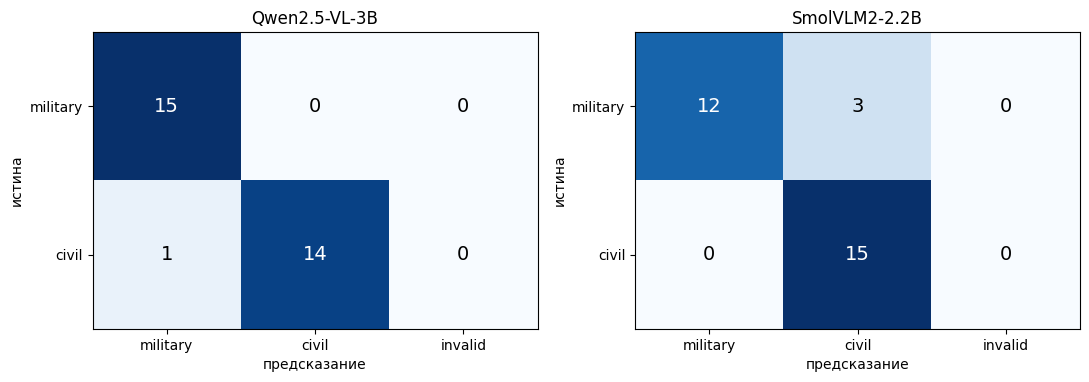

In [22]:
fig, axes = plt.subplots(1, len(results), figsize=(5.5 * len(results), 4))
axes = np.atleast_1d(axes)
cols = ["military", "civil", "invalid"]
for ax, (name, res) in zip(axes, results.items()):
    m = labels.merge(res, on="file")
    cm = confusion_matrix(m["true_label"], m["pred"], labels=cols)[:2]   # строки: military, civil
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(cols)
    ax.set_yticks(range(2)); ax.set_yticklabels(["military", "civil"])
    ax.set_xlabel("предсказание"); ax.set_ylabel("истина"); ax.set_title(name)
    for i in range(2):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

## 7. Сравнительный анализ и исследование ошибок

На этом этапе результаты двух моделей объединяются с исходной разметкой. Сравнивается, на каких изображениях обе модели дали правильный ответ, где ошиблась только одна модель и где ошиблись обе. Отдельно рассматриваются показатели на простых и нетривиальных случаях.

Также анализируется связь между заявленной моделями уверенностью и фактической правильностью ответа. Значение confidence формируется самой моделью и не является калиброванной вероятностью.

In [23]:
comp = labels[["file", "true_label", "aircraft_model", "hard", "note"]].copy()
for tag, (name, res) in zip("AB", results.items()):
    r = res.set_index("file")
    comp[f"pred_{tag}"] = comp["file"].map(r["pred"])
    comp[f"conf_{tag}"] = comp["file"].map(r["confidence"])
    comp[f"ok_{tag}"] = comp[f"pred_{tag}"] == comp["true_label"]

print(f"A = {NAME_A}, B = {NAME_B}")
print("Обе верно:       ", int((comp.ok_A & comp.ok_B).sum()))
print("Только A верно:  ", int((comp.ok_A & ~comp.ok_B).sum()))
print("Только B верно:  ", int((~comp.ok_A & comp.ok_B).sum()))
print("Обе ошиблись:    ", int((~comp.ok_A & ~comp.ok_B).sum()))
print("Совпадение ответов моделей:", round((comp.pred_A == comp.pred_B).mean(), 3))

errors = comp[~(comp.ok_A & comp.ok_B)]
display(errors[["file", "aircraft_model", "true_label", "pred_A", "pred_B", "conf_A", "conf_B", "note"]])
comp.to_csv("comparison.csv", index=False, encoding="utf-8-sig")

A = Qwen2.5-VL-3B, B = SmolVLM2-2.2B
Обе верно:        26
Только A верно:   3
Только B верно:   1
Обе ошиблись:     0
Совпадение ответов моделей: 0.867


,file,aircraft_model,true_label,pred_A,pred_B,conf_A,conf_B,note
5,img_06.jpg,Airbus A330 MRTT,military,military,civil,0.95,0.95,заправщик на базе пассажирского A330 (нетривиа...
8,img_09.jpg,Ан-26,military,military,civil,0.95,0.95,проверить оператора и окраску (нетривиальный)
9,img_10.jpg,Beechcraft T-6 Texan II,military,military,civil,0.95,0.95,учебно-тренировочный (нетривиальный)
19,img_20.jpg,Ил-76ТД,civil,military,civil,0.95,0.95,гражданская ливрея (нетривиальный)


In [24]:
# уверенность при верных и неверных ответах (калибровка)
for tag, name in zip("AB", results):
    d = comp.groupby(f"ok_{tag}")[f"conf_{tag}"].mean().round(3).to_dict()
    print(f"{name}: средний confidence | верно = {d.get(True)}, ошибка = {d.get(False)}")

Qwen2.5-VL-3B: средний confidence | верно = 0.95, ошибка = 0.95
SmolVLM2-2.2B: средний confidence | верно = 0.95, ошибка = 0.95


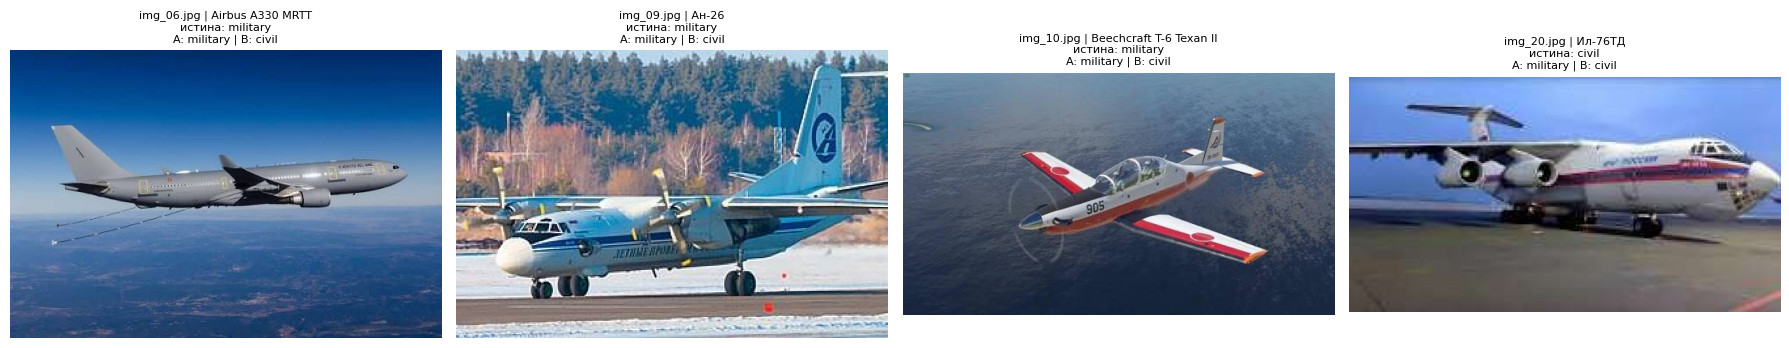

In [25]:
# фото, на которых ошиблась хотя бы одна модель
n = len(errors)
if n:
    cols_n = 4
    rows_n = (n + cols_n - 1) // cols_n
    fig, axes = plt.subplots(rows_n, cols_n, figsize=(4.5 * cols_n, 3.6 * rows_n))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, errors.iterrows()):
        ax.imshow(Image.open(os.path.join(IMG_DIR, r["file"])).convert("RGB"))
        ax.set_title(f'{r["file"]} | {r["aircraft_model"]}\nистина: {r["true_label"]}\n'
                     f'A: {r["pred_A"]} | B: {r["pred_B"]}', fontsize=8)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("errors_grid.png", dpi=150)
    plt.show()
else:
    print("Ошибок нет")

## 8. Результаты эксперимента и интерпретация

По сохранённой сводке метрик получены следующие значения:

| Модель | Выборка | n | Accuracy | Precision | Recall | F1-score |
|:--|:--|--:|--:|--:|--:|--:|
| Qwen2.5-VL-3B | Все изображения | 30 | **0,967** | 0,938 | **1,000** | **0,968** |
| SmolVLM2-2.2B | Все изображения | 30 | 0,900 | **1,000** | 0,800 | 0,889 |
| Qwen2.5-VL-3B | Простые случаи | 8 | 1,000 | 1,000 | 1,000 | 1,000 |
| SmolVLM2-2.2B | Простые случаи | 8 | 1,000 | 1,000 | 1,000 | 1,000 |
| Qwen2.5-VL-3B | Нетривиальные случаи | 22 | **0,955** | 0,923 | **1,000** | **0,960** |
| SmolVLM2-2.2B | Нетривиальные случаи | 22 | 0,864 | **1,000** | 0,750 | 0,857 |

На всей выборке Qwen2.5-VL-3B показала более высокую Accuracy (96,7% против 90,0%) и Recall для класса `military` (100% против 80,0%). SmolVLM2-2.2B получила Precision 100%: в рамках этой выборки все её предсказания класса `military` оказались верными, однако часть военных самолётов модель не распознала.

На простых примерах обе модели достигли 100% Accuracy. Различия проявились на нетривиальных изображениях: Accuracy Qwen составила 95,5%, SmolVLM2 — 86,4%. Это указывает на то, что сложные и неоднозначные визуальные случаи сильнее влияют на итоговое качество.

**Интерпретация ограничена размером выборки.** В эксперименте использовано только 30 изображений, поэтому полученные значения характеризуют данный набор данных и не гарантируют аналогичное качество на произвольных фотографиях самолётов.

## 9. Выводы

1. Обе модели корректно классифицировали все 8 простых примеров.
2. На полной выборке более высокое качество по Accuracy и F1-score показала Qwen2.5-VL-3B.
3. На нетривиальных примерах преимущество Qwen сохранилось: 95,5% Accuracy против 86,4% у SmolVLM2.
4. SmolVLM2 продемонстрировала более высокую Precision для класса `military`, но более низкий Recall, то есть чаще пропускала военные самолёты.
5. Для более надёжного сравнения необходимо увеличить выборку, расширить разнообразие типов самолётов и проверить устойчивость результатов на независимом наборе изображений.

Таким образом, в рамках проведённого эксперимента Qwen2.5-VL-3B оказалась более точной моделью для рассматриваемой задачи. Вывод относится только к использованной выборке и настройкам эксперимента.


## 10. Экспорт результатов

Итоговые таблицы и графики сохраняются в архив. Они включают предсказания обеих моделей, сводные метрики, сравнительную таблицу, матрицы ошибок и изображения случаев, в которых хотя бы одна модель допустила ошибку. Эти материалы используются для документирования и дальнейшего анализа эксперимента.

In [26]:
import shutil
os.makedirs("out", exist_ok=True)
for f in ["results_qwen.csv", "results_smolvlm.csv", "metrics_summary.csv",
          "comparison.csv", "confusion_matrices.png", "errors_grid.png"]:
    if os.path.exists(f):
        shutil.copy(f, "out/")
shutil.make_archive("results", "zip", "out")
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>